# Lab 03: Logistic Regression — Email Spam Detection

This laboratory project explores binary classification for email spam filtering using regularized Logistic Regression with standardized numerical features.

### Objectives:
1. Ingest structural email metadata and lexicon frequency features.
2. Exploratory data analysis, duplicate verification, and class balance.
3. Feature scaling using `StandardScaler` to normalize feature magnitudes.
4. Training Logistic Regression with L2 regularization.
5. Evaluation using Confusion Matrix, Accuracy, and Classification Report.
6. Coefficient weights analysis for feature importance interpretability.
7. Making calibrated probability predictions on new email samples.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load email features dataset
df = pd.read_csv("data.csv")
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())


Dataset Shape: (300, 11)

First 5 records:


,text_length,num_links,num_exclamations,num_uppercase_words,spam_word_count,has_currency,is_reply,sender_in_contacts,has_attachment,hour_sent,result
0,185,1,3,0,2,1,0,0,0,8,1
1,179,0,1,0,0,0,0,1,0,14,0
2,171,1,1,1,5,1,0,0,0,12,1
3,190,0,0,0,0,0,1,1,0,18,0
4,185,0,0,0,0,0,0,1,1,11,0


In [2]:
# Dataset inspection and class balance
print("Class distribution ('result': 0 = Legitimate, 1 = Spam):")
print(df["result"].value_counts(normalize=True).round(3))
print(f"\nDuplicate records count: {df.duplicated().sum()}")
print(f"Missing values count: {df.isnull().sum().sum()}")


Class distribution ('result': 0 = Legitimate, 1 = Spam):
result
1    0.5
0    0.5
Name: proportion, dtype: float64

Duplicate records count: 0
Missing values count: 0


In [3]:
# Feature definition and train/test split
features = ['text_length', 'num_links', 'num_exclamations', 'num_uppercase_words',
            'spam_word_count', 'has_currency', 'is_reply', 'sender_in_contacts',
            'has_attachment', 'hour_sent']

X = df[features]
y = df['result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Standardization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train samples: {X_train.shape[0]}, Test samples: {X_test.shape[0]}")


Train samples: 240, Test samples: 60


In [4]:
# Train Logistic Regression model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Predict class and probabilities
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Model Evaluation:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Legitimate (0)', 'Spam (1)'], zero_division=0))


Model Evaluation:
Accuracy: 0.9667

Classification Report:
                precision    recall  f1-score   support

Legitimate (0)       0.97      0.97      0.97        30
      Spam (1)       0.97      0.97      0.97        30

      accuracy                           0.97        60
     macro avg       0.97      0.97      0.97        60
  weighted avg       0.97      0.97      0.97        60



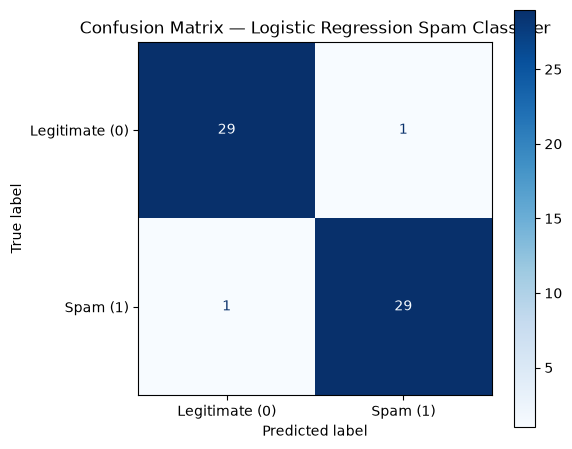

In [5]:
# Confusion Matrix Display
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate (0)', 'Spam (1)'])
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix — Logistic Regression Spam Classifier', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()


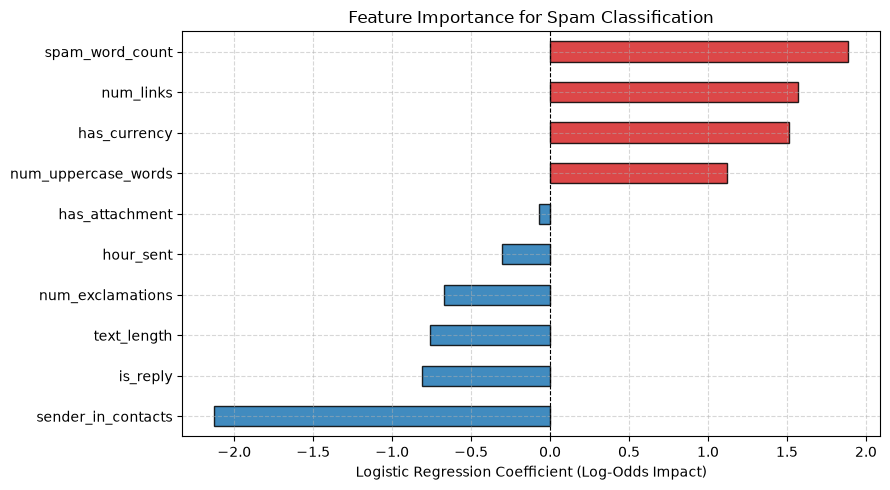

Learned Feature Coefficients:
sender_in_contacts    -2.128850
is_reply              -0.810508
text_length           -0.761718
num_exclamations      -0.672956
hour_sent             -0.302530
has_attachment        -0.068964
num_uppercase_words    1.119752
has_currency           1.510946
num_links              1.568485
spam_word_count        1.888366
dtype: float64


In [6]:
# Feature Importance: Model Coefficients
coef_series = pd.Series(model.coef_[0], index=features).sort_values()

plt.figure(figsize=(9, 5))
colors = ['#d62728' if x > 0 else '#1f77b4' for x in coef_series.values]
coef_series.plot(kind='barh', color=colors, edgecolor='k', alpha=0.85)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel('Logistic Regression Coefficient (Log-Odds Impact)')
plt.title('Feature Importance for Spam Classification', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Learned Feature Coefficients:")
print(coef_series)


In [7]:
# Inference on a new email sample
# Example: text_length=210, links=1, exclamations=3, uppercase=4, spam_words=5, currency=1, is_reply=0, in_contacts=0, attachment=0, hour=3
new_email = pd.DataFrame([[210, 1, 3, 4, 5, 1, 0, 0, 0, 3]], columns=features)
new_scaled = scaler.transform(new_email)

prediction = model.predict(new_scaled)[0]
probabilities = model.predict_proba(new_scaled)[0]

print(f"Predicted Class: {'SPAM (1)' if prediction == 1 else 'LEGITIMATE (0)'}")
print(f"Probabilities -> P(Legitimate): {probabilities[0]:.4f}, P(Spam): {probabilities[1]:.4f}")


Predicted Class: SPAM (1)
Probabilities -> P(Legitimate): 0.0000, P(Spam): 1.0000
